# Early Sepsis Risk Prediction: Overall Metrics
This notebook displays the official patient-level temporal evaluation for the production XGBoost model. The test set was not used for training or threshold selection.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
REPORT = ROOT / 'reports' / 'final_temporal_patient_evaluation_report.json'
report = json.loads(REPORT.read_text(encoding='utf-8'))
metrics = report['metrics']
print('Model: XGBoost')
print('Evaluation: patient-level temporal test split')
print('Patients:', report['patients'])
print('Threshold:', report['threshold'])
print('Required consecutive observations:', report['required_consecutive'])

Model: XGBoost
Evaluation: patient-level temporal test split
Patients: 6051
Threshold: 0.6
Required consecutive observations: 2


In [2]:
overall = pd.DataFrame({'Metric':['Accuracy','Precision','Recall','F1 score','Specificity','ROC-AUC','PR-AUC'], 'Score':[metrics['accuracy'],metrics['precision'],metrics['recall'],metrics['f1_score'],metrics['specificity'],metrics['roc_auc'],metrics['pr_auc']]})
overall['Percentage'] = (overall['Score'] * 100).round(2)
display(overall[['Metric','Percentage']])

,Metric,Percentage
0,Accuracy,91.27
1,Precision,41.91
2,Recall,51.82
3,F1 score,46.34
4,Specificity,94.37
5,ROC-AUC,86.13
6,PR-AUC,52.99


,Predicted non-sepsis,Predicted sepsis
Actual non-sepsis,5295,316
Actual sepsis,212,228


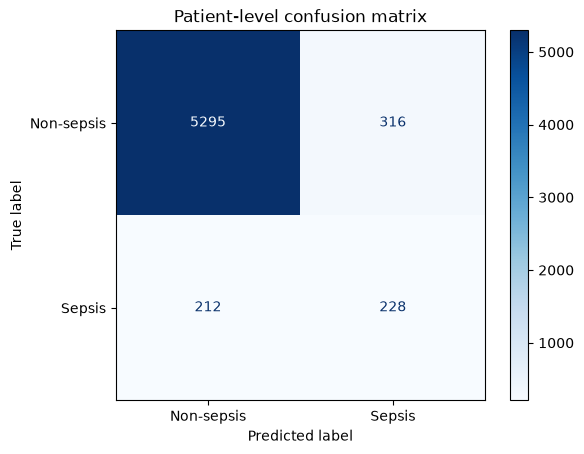

In [3]:
confusion = pd.DataFrame([[metrics['true_negatives'],metrics['false_positives']],[metrics['false_negatives'],metrics['true_positives']]], index=['Actual non-sepsis','Actual sepsis'], columns=['Predicted non-sepsis','Predicted sepsis'])
display(confusion)
ConfusionMatrixDisplay(confusion.values, display_labels=['Non-sepsis','Sepsis']).plot(cmap='Blues')
plt.title('Patient-level confusion matrix')
plt.show()

In [4]:
operational = pd.DataFrame({'Measure':['Alerts per patient','False alerts per ICU stay','Detected before onset','Detected at least 3h before','Detected at least 6h before','Detected at least 12h before','Median lead time (hours)'], 'Value':[metrics['alerts_per_patient'],metrics['false_alerts_per_icu_stay'],metrics['detected_before_onset'],metrics['detected_at_least_3h_before'],metrics['detected_at_least_6h_before'],metrics['detected_at_least_12h_before'],metrics['median_lead_time_hours']]})
display(operational)

,Measure,Value
0,Alerts per patient,3.694926
1,False alerts per ICU stay,1.726430
2,Detected before onset,177.000000
3,Detected at least 3h before,176.000000
4,Detected at least 6h before,169.000000
5,Detected at least 12h before,160.000000
6,Median lead time (hours),29.500000


## Interpretation
Recall measures how many sepsis patients were detected. Precision measures how many alerts were truly sepsis cases. Specificity measures correct identification of non-sepsis patients. Accuracy is reported for completeness, but it should not be interpreted alone because non-sepsis patients are much more common.

The production Streamlit model remains unchanged by this notebook.